<div style="background-color: #FAF7F2; border: 2px solid #E8DFD1; border-radius: 16px; padding: 28px 24px; margin-bottom: 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;">
  <div style="display: flex; align-items: center; justify-content: space-between; flex-wrap: wrap; gap: 16px; border-bottom: 1px solid #E8DFD1; padding-bottom: 18px; margin-bottom: 18px;">
    <div>
      <span style="font-family: monospace; font-size: 11px; text-transform: uppercase; letter-spacing: 0.14em; color: #D56638; font-weight: 700;">USTP CDO • College of Science & Technology</span>
      <h1 style="font-size: 26px; font-weight: 800; color: #2A2825; margin: 6px 0 2px 0; letter-spacing: -0.02em;">Topic 01 Field Journal: Introduction to Exploratory Data Analysis</h1>
      <p style="font-size: 14px; color: #7D756D; margin: 4px 0 0 0; font-style: italic;">The Philosophy of Looking: How John Tukey's Four R's & Francis Anscombe's 1973 Wake-Up Call Cured My Dataset-Hopping Panic</p>
    </div>
    <div style="display: flex; align-items: center; gap: 14px; background: #FFFFFF; padding: 10px 18px; border-radius: 50px; border: 1px solid #E8DFD1; box-shadow: 0 4px 12px rgba(42, 40, 37, 0.05);">
      <img src="assets/images/author/pfp_kuno.jpg" alt="Rogelio Mandamian" style="width: 50px; height: 50px; border-radius: 50%; object-fit: cover; border: 2px solid #D56638;" />
      <div>
        <div style="font-weight: 800; font-size: 14px; color: #2A2825;">Rogelio Mandamian</div>
        <div style="font-size: 11px; color: #D56638; font-weight: 700; letter-spacing: 0.05em;">BS Data Science • DS3A</div>
      </div>
    </div>
  </div>
  <div style="display: flex; gap: 24px; flex-wrap: wrap; font-size: 12px; color: #7D756D;">
    <div><strong>Course:</strong> DS311 Exploratory Data Analysis</div>
    <div><strong>Curriculum Focus:</strong> Topic 01 — Introduction to EDA</div>
    <div><strong>Instructor:</strong> Ma'am Chris Jallaine S. Mugot</div>
    <div><strong>Repository:</strong> <a href="https://github.com/Troge-dev" style="color: #D56638; text-decoration: none; font-weight: 600;">github.com/Troge-dev</a></div>
  </div>
</div>

---

## The Confession: The Trap of Confirmatory Rushing & Dataset-Hopping

Let's begin with an honest admission from a 3rd-year data science student:

During our earlier **DATAVIS** course, I did not know what Exploratory Data Analysis genuinely meant. Whenever we were assigned a project, my workflow was completely backward:
1. Hunt for a dataset on Kaggle with an appealing title.
2. Load it into a notebook and immediately ask: *"Does this confirm my preconceived hypothesis?"*
3. Rush straight into multivariate correlations, high-dimensional projections, or complex charts without ever inspecting the individual columns.
4. The moment missing values appeared, bizarre scale distortions arose, or numbers looked weird, I panicked. I treated missingness like an error to be covered up with a quick `fillna(mean)`.
5. When that inevitably broke my models or produced nonsensical conclusions, I concluded the dataset was "broken" and abandoned it.

I fell into chronic **dataset-hopping**. We cycled through multiple dead ends until we finally stumbled upon the **Egypt Population Density dataset**. 

Finding the Egypt dataset felt like striking gold back then—it was structured, coherent, and allowed us to build an impressive visual map of Egypt's demographic concentration along the Nile corridor. But when I entered **DS311** and our instructor, **Ma'am Chris Jallaine S. Mugot**, walked us through **Topic 01 (Introduction to EDA)**, the real truth hit me:

> **In DATAVIS, I had gotten lucky by hopping around until I stumbled upon a dataset that didn't intimidate me. But running away from messy data is running away from data science itself.**

Ma'am Chris introduced us to John Tukey (1977) and Francis Anscombe (1973), instilling the single most transformative lesson of my academic journey:
**EDA is never a rigid technique or a confirmatory checklist—it is an approach. Data must be seen, not just calculated.**

This notebook is my hands-on executable field journal documenting the core foundations of Topic 01: Anscombe's Quartet, Tukey's Four R's, and the non-linear cycle of questions that permanently cured my dataset-hopping panic.

In [1]:
# Step 0: Minimalist Visual Environment Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set high-resolution display and Minimalist Baker warm aesthetic
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

PALETTE = {
    'canvas': '#FAF7F2',
    'surface': '#FFFFFF',
    'terracotta': '#D56638',
    'olive': '#5A822B',
    'charcoal': '#2A2825',
    'muted': '#7D756D',
    'grid': '#F3EDE2',
    'border': '#E8DFD1'
}

print("Minimalist EDA Environment Loaded! Ready for Topic 01 Foundations.")

Minimalist EDA Environment Loaded! Ready for Topic 01 Foundations.


---
## When Numbers Mislead: Francis Anscombe's 1973 Wake-Up Call

In data analysis, it is tempting to rely purely on summary statistics: means, variances, correlation coefficients ($r$), and regression slopes ($eta_1$). These numbers give the illusion of complete understanding.

In 1973, statistician Francis Anscombe published *"Graphs in Statistical Analysis"* in *The American Statistician* specifically to demolish this false sense of security. He constructed four synthetic datasets, each with $N=11$ coordinate pairs $(x, y)$, where the summary statistics are identical to three decimal places:

| Summary Statistic | Value Across All 4 Datasets |
| :--- | :--- |
| **Number of Points ($N$)** | $11$ |
| **Mean of $X$ ($\mu_X$)** | $9.00$ |
| **Mean of $Y$ ($\mu_Y$)** | $7.50$ |
| **Sample Variance of $X$ ($s^2_X$)** | $11.00$ |
| **Sample Variance of $Y$ ($s^2_Y$)** | $4.125$ |
| **Pearson Correlation ($r$)** | $0.816$ |
| **OLS Regression Line** | $y = 3.00 + 0.50x$ |
| **Coefficient of Determination ($R^2$)** | $66.6\%$ |

If you were a "numbers-only" analyst, you would declare that all four datasets are virtually identical. Let's build the datasets in Python and verify their mathematical equivalence:

In [2]:
# Constructing Anscombe's Quartet (1973)
anscombe_data = {
    'x1': [10.0, 8.0, 13.0, 9.0, 11.0, 14.0, 6.0, 4.0, 12.0, 7.0, 5.0],
    'y1': [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
    
    'x2': [10.0, 8.0, 13.0, 9.0, 11.0, 14.0, 6.0, 4.0, 12.0, 7.0, 5.0],
    'y2': [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
    
    'x3': [10.0, 8.0, 13.0, 9.0, 11.0, 14.0, 6.0, 4.0, 12.0, 7.0, 5.0],
    'y3': [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
    
    'x4': [8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 19.0],
    'y4': [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 5.56, 7.91, 6.89, 12.50]
}

# Compile summary statistics for each dataset
records = []
for i in range(1, 5):
    x = np.array(anscombe_data[f'x{i}'])
    y = np.array(anscombe_data[f'y{i}'])
    slope, intercept, r_val, p_val, std_err = stats.linregress(x, y)
    records.append({
        'Dataset': f'Dataset {i}',
        'Mean X': round(np.mean(x), 2),
        'Mean Y': round(np.mean(y), 2),
        'Var X': round(np.var(x, ddof=1), 2),
        'Var Y': round(np.var(y, ddof=1), 3),
        'Pearson r': round(r_val, 3),
        'OLS Line': f"y = {intercept:.2f} + {slope:.2f}x",
        'R-squared': f"{r_val**2:.3f}"
    })

df_anscombe_stats = pd.DataFrame(records)
print("--- SUMMARY STATISTICS OF ANSCOMBE'S QUARTET ---")
display(df_anscombe_stats)

--- SUMMARY STATISTICS OF ANSCOMBE'S QUARTET ---
  Dataset  Mean X  Mean Y  Var X  Var Y  Pearson r         OLS Line R-squared
Dataset 1     9.0     7.5   11.0  4.127      0.816 y = 3.00 + 0.50x     0.667
Dataset 2     9.0     7.5   11.0  4.128      0.816 y = 3.00 + 0.50x     0.666
Dataset 3     9.0     7.5   11.0  4.123      0.816 y = 3.00 + 0.50x     0.666
Dataset 4     9.0     7.5   11.0  4.123      0.817 y = 3.00 + 0.50x     0.667


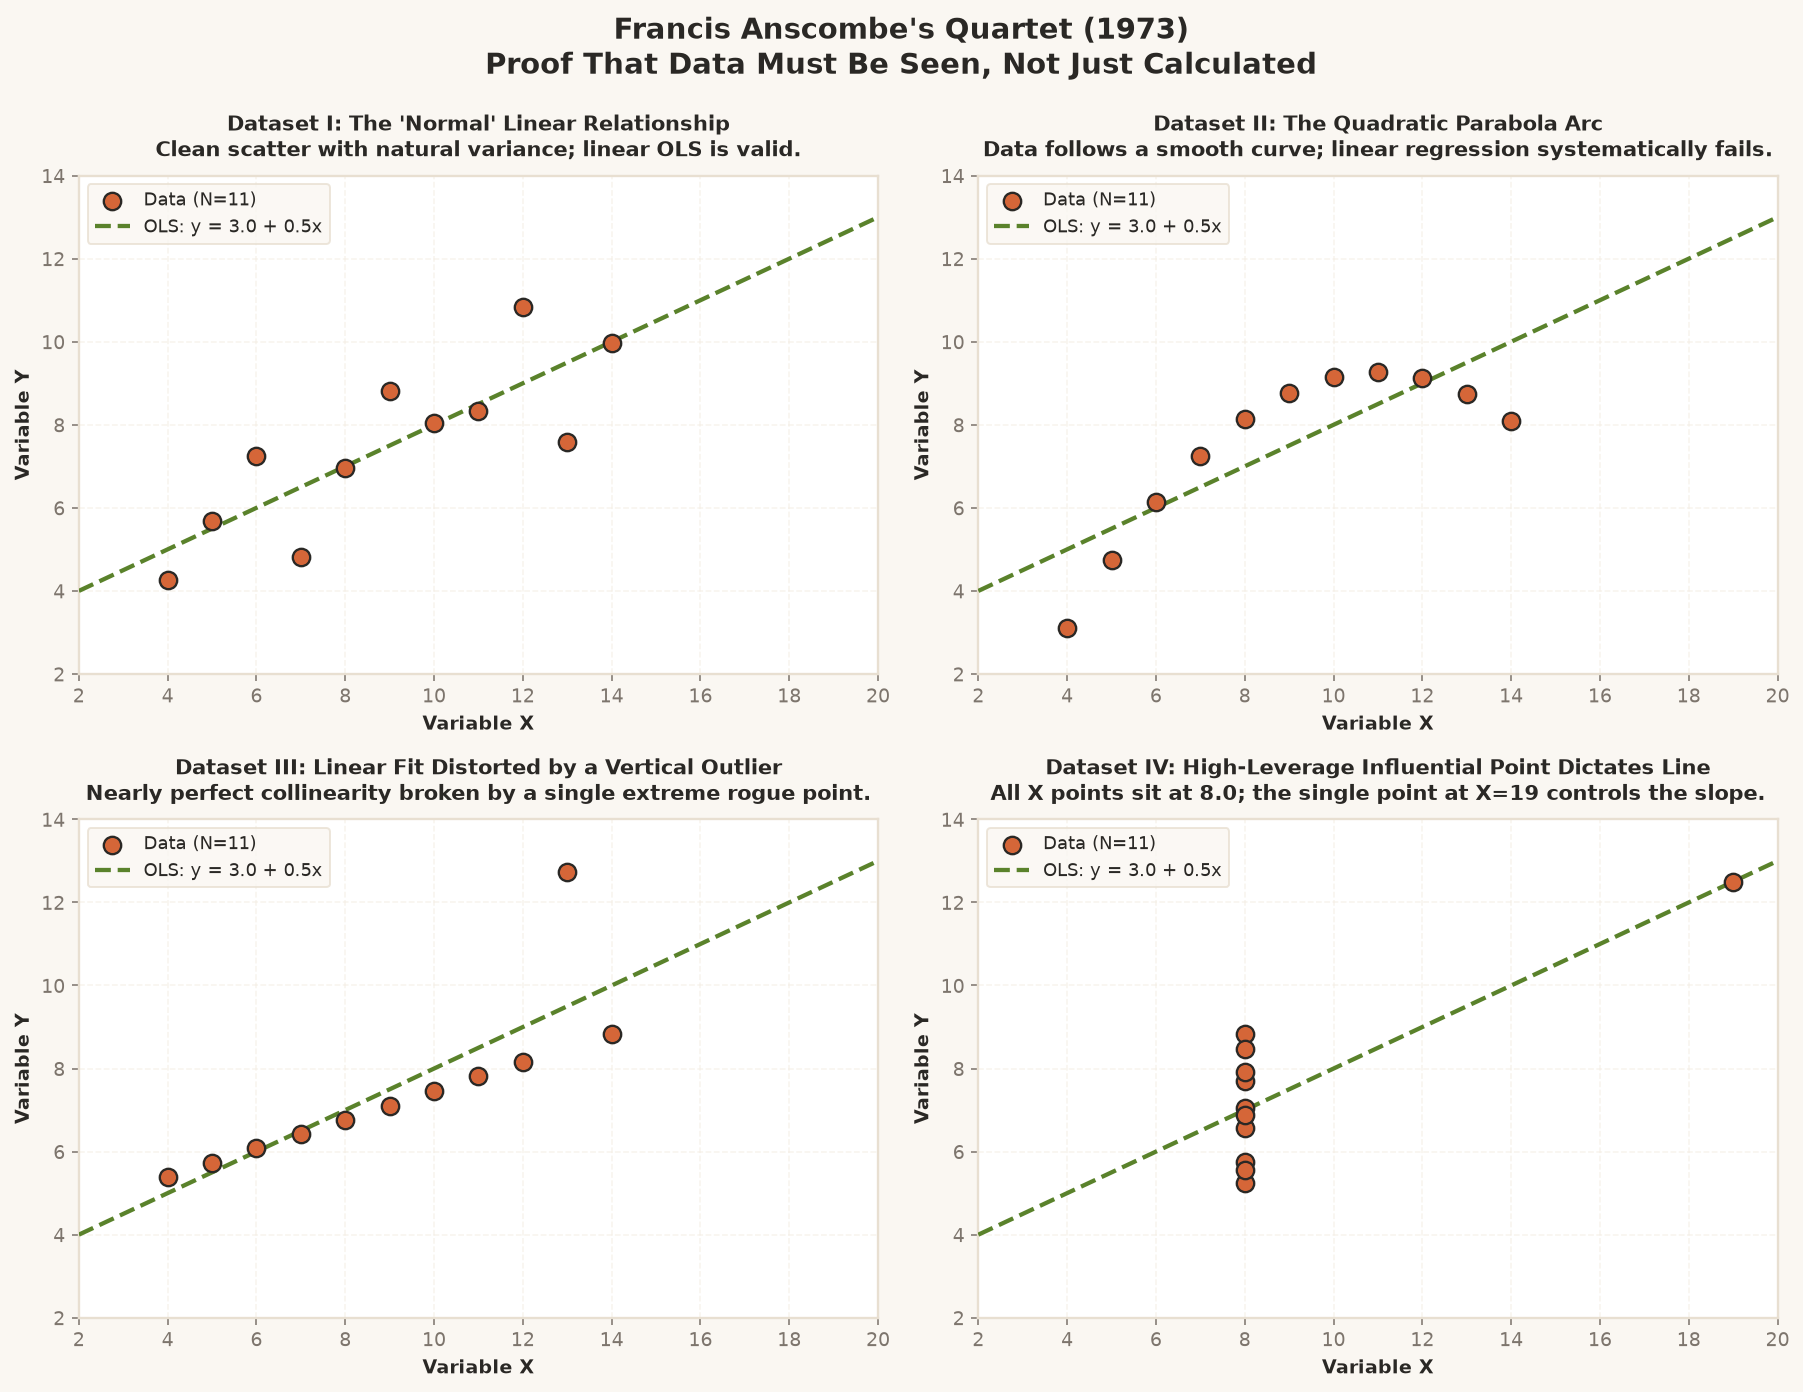

In [3]:
# Plotting Francis Anscombe's Quartet Side-by-Side
fig, axes = plt.subplots(2, 2, figsize=(13, 10), facecolor=PALETTE['canvas'])

titles = [
    "Dataset I: The 'Normal' Linear Relationship",
    "Dataset II: The Quadratic Parabola Arc",
    "Dataset III: Linear Fit Distorted by a Vertical Outlier",
    "Dataset IV: High-Leverage Influential Point Dictates Line"
]
subtitles = [
    "Clean scatter with natural variance; linear OLS is valid.",
    "Data follows a smooth curve; linear regression systematically fails.",
    "Nearly perfect collinearity broken by a single extreme rogue point.",
    "All X points sit at 8.0; the single point at X=19 controls the slope."
]

x_line = np.linspace(2, 20, 100)
y_line = 3.00 + 0.50 * x_line

for i, ax in enumerate(axes.flat, 1):
    ax.set_facecolor(PALETTE['surface'])
    x = np.array(anscombe_data[f'x{i}'])
    y = np.array(anscombe_data[f'y{i}'])
    
    ax.scatter(x, y, s=80, color=PALETTE['terracotta'], edgecolor=PALETTE['charcoal'], linewidth=1.2, zorder=4, label='Data (N=11)')
    ax.plot(x_line, y_line, color=PALETTE['olive'], linewidth=2.2, linestyle='--', zorder=3, label='OLS: y = 3.0 + 0.5x')
    
    ax.set_title(f"{titles[i-1]}\n{subtitles[i-1]}", fontsize=11, fontweight='bold', color=PALETTE['charcoal'], pad=10)
    ax.set_xlim(2, 20)
    ax.set_ylim(2, 14)
    ax.set_xlabel('Variable X', fontsize=10, fontweight='600')
    ax.set_ylabel('Variable Y', fontsize=10, fontweight='600')
    ax.legend(loc='upper left', frameon=True, facecolor=PALETTE['canvas'], edgecolor=PALETTE['border'], fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.6, color=PALETTE['grid'])

plt.suptitle("Francis Anscombe's Quartet (1973)\nProof That Data Must Be Seen, Not Just Calculated", 
             fontsize=15, fontweight='bold', color=PALETTE['charcoal'], y=0.99)
plt.tight_layout()
plt.show()

---
## Seeing Data Before Deciding: John Tukey's Four R's of EDA

In his 1977 landmark book *Exploratory Data Analysis*, statistician **John Tukey** formalized the discipline. He argued that data analysis should not begin with rigid assumptions or predefined hypotheses. Instead, it must begin with open-ended exploration:

> **"Instead of immediately asking, 'Does this confirm my hypothesis?', EDA asks, 'What is this data trying to tell me?'"**

Tukey encapsulated the foundational philosophy of EDA into **The Four R's**:

1. **Resistance:** A good analysis must not be hijacked by extreme outliers. Summary statistics must reflect the bulk of the data (e.g., favoring the Median over the Mean).
2. **Residuals:** Whenever you fit any model or pattern, examine what is left over. $\text{Data} = \text{Fit} + \text{Residual}$. What the fit missed is often the most informative part!
3. **Re-expression:** The form your data arrives in is not necessarily the best form for understanding it. Transforming skewed variables (e.g., logarithmic transforms) reveals underlying structure.
4. **Revelation:** The ultimate goal is making the invisible visible through graphical displays. Revelation ties everything together.

Let's write runnable Python demonstrations for each of Tukey's Four R's:

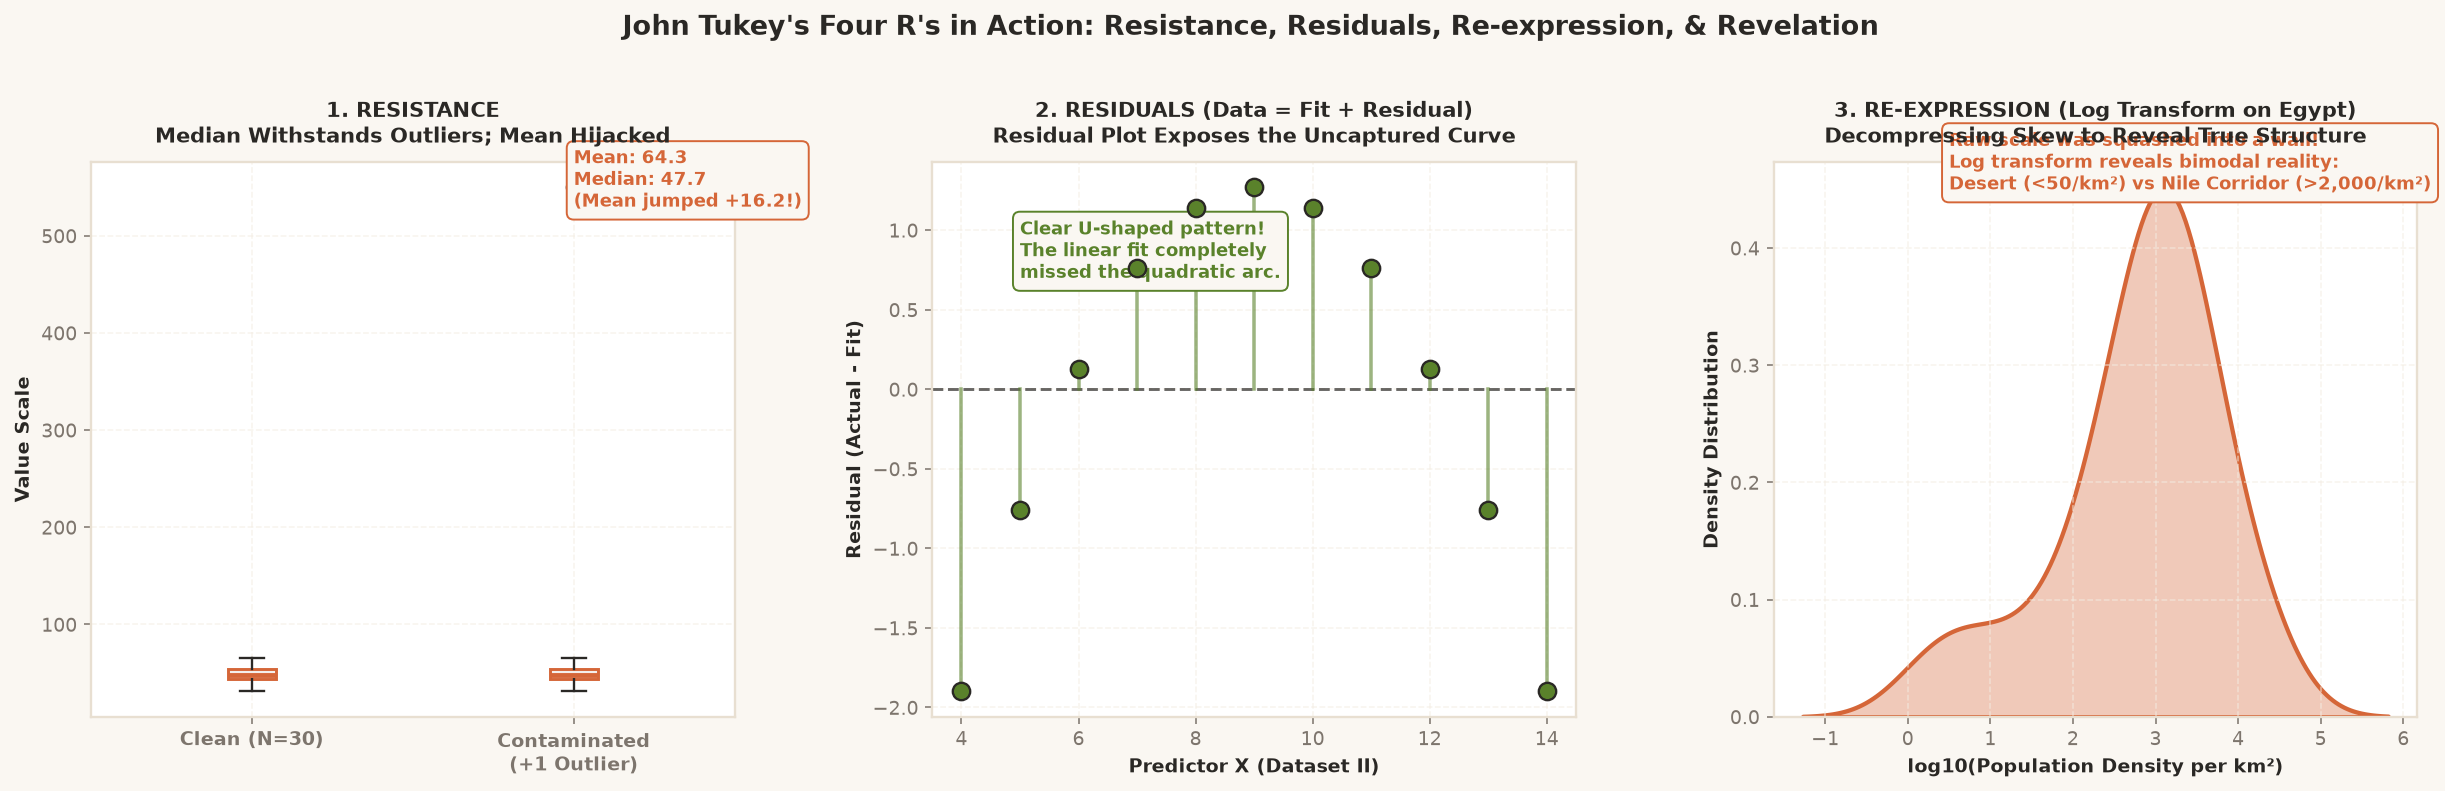

In [4]:
# Python Demonstration of John Tukey's Four R's:
# 1. Resistance: Median vs Mean under extreme outlier contamination
# 2. Residuals: Plotting (Data - Fit) on Anscombe Dataset II
# 3. Re-expression: Log10 transform on skewed Egypt Population Density
# 4. Revelation: Visualizing all three side-by-side!

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), facecolor=PALETTE['canvas'])

# 1. RESISTANCE DEMONSTRATION
ax1 = axes[0]
ax1.set_facecolor(PALETTE['surface'])
clean_vals = np.random.normal(50, 10, 30)
contaminated_vals = np.append(clean_vals, [550]) # single extreme outlier

ax1.boxplot([clean_vals, contaminated_vals], patch_artist=True,
            boxprops=dict(facecolor='#F4EFEB', color=PALETTE['terracotta'], linewidth=1.5),
            medianprops=dict(color=PALETTE['terracotta'], linewidth=2.5),
            whiskerprops=dict(color=PALETTE['charcoal'], linewidth=1.2),
            capprops=dict(color=PALETTE['charcoal'], linewidth=1.2),
            flierprops=dict(marker='o', markerfacecolor=PALETTE['terracotta'], markersize=8))
ax1.set_xticklabels(['Clean (N=30)', 'Contaminated\n(+1 Outlier)'], fontsize=10, fontweight='600')
ax1.set_title("1. RESISTANCE\nMedian Withstands Outliers; Mean Hijacked", fontsize=11, fontweight='bold', color=PALETTE['charcoal'], pad=10)
ax1.set_ylabel("Value Scale", fontsize=10, fontweight='600')
ax1.text(2, 530, f"Mean: {contaminated_vals.mean():.1f}\nMedian: {np.median(contaminated_vals):.1f}\n(Mean jumped +{contaminated_vals.mean()-clean_vals.mean():.1f}!)", 
         color=PALETTE['terracotta'], fontsize=9, fontweight='bold', bbox=dict(facecolor=PALETTE['canvas'], edgecolor=PALETTE['terracotta'], boxstyle='round,pad=0.4'))
ax1.grid(True, linestyle='--', alpha=0.6, color=PALETTE['grid'])

# 2. RESIDUALS DEMONSTRATION
ax2 = axes[1]
ax2.set_facecolor(PALETTE['surface'])
x2 = np.array(anscombe_data['x2'])
y2 = np.array(anscombe_data['y2'])
fit2 = 3.0 + 0.5 * x2
residuals2 = y2 - fit2

ax2.axhline(0, color=PALETTE['charcoal'], linestyle='--', linewidth=1.5, alpha=0.7)
ax2.scatter(x2, residuals2, s=80, color=PALETTE['olive'], edgecolor=PALETTE['charcoal'], linewidth=1.2, zorder=4)
for xi, resi in zip(x2, residuals2):
    ax2.plot([xi, xi], [0, resi], color=PALETTE['olive'], linestyle='-', alpha=0.6, linewidth=1.8)

ax2.set_title("2. RESIDUALS (Data = Fit + Residual)\nResidual Plot Exposes the Uncaptured Curve", fontsize=11, fontweight='bold', color=PALETTE['charcoal'], pad=10)
ax2.set_xlabel("Predictor X (Dataset II)", fontsize=10, fontweight='600')
ax2.set_ylabel("Residual (Actual - Fit)", fontsize=10, fontweight='600')
ax2.text(5, 0.7, "Clear U-shaped pattern!\nThe linear fit completely\nmissed the quadratic arc.", 
         color=PALETTE['olive'], fontsize=9, fontweight='bold', bbox=dict(facecolor=PALETTE['canvas'], edgecolor=PALETTE['olive'], boxstyle='round,pad=0.4'))
ax2.grid(True, linestyle='--', alpha=0.6, color=PALETTE['grid'])

# 3. RE-EXPRESSION DEMONSTRATION (EGYPT POPULATION DENSITY)
ax3 = axes[2]
ax3.set_facecolor(PALETTE['surface'])
egypt_densities = np.array([
    19500, 14200, 8900, 4200, 3100, 2800, 2500, 2200, 1950, 1800,
    1600, 1400, 1200, 950, 850, 750, 650, 550, 450, 350,
    220, 180, 95, 45, 12.5, 4.2, 1.8
])
log_densities = np.log10(egypt_densities)

sns.kdeplot(log_densities, ax=ax3, color=PALETTE['terracotta'], fill=True, alpha=0.35, linewidth=2.2)
ax3.set_title("3. RE-EXPRESSION (Log Transform on Egypt)\nDecompressing Skew to Reveal True Structure", fontsize=11, fontweight='bold', color=PALETTE['charcoal'], pad=10)
ax3.set_xlabel("log10(Population Density per km²)", fontsize=10, fontweight='600')
ax3.set_ylabel("Density Distribution", fontsize=10, fontweight='600')
ax3.text(0.5, 0.45, "Raw scale was squashed into a wall!\nLog transform reveals bimodal reality:\nDesert (<50/km²) vs Nile Corridor (>2,000/km²)", 
         color=PALETTE['terracotta'], fontsize=9, fontweight='bold', bbox=dict(facecolor=PALETTE['canvas'], edgecolor=PALETTE['terracotta'], boxstyle='round,pad=0.4'))
ax3.grid(True, linestyle='--', alpha=0.6, color=PALETTE['grid'])

plt.suptitle("John Tukey's Four R's in Action: Resistance, Residuals, Re-expression, & Revelation", 
             fontsize=14, fontweight='bold', color=PALETTE['charcoal'], y=1.02)
plt.tight_layout()
plt.show()

---
## A Cycle of Questions: Why EDA Is Not Linear & The 7 Common Steps

In formal mathematics and standard coursework, students are trained to follow rigid procedures: take the equation, substitute the parameters, and arrive at the single right answer.

As Ma'am Chris emphasized throughout Topic 01, **Exploratory Data Analysis does not work that way**:
- It is not governed by a universal checklist or a rigid recipe book.
- It is shaped by the data itself, the domain context, and the anomalies discovered along the way.
- Two skilled analysts working on the exact same dataset can choose different exploration paths and both be completely valid.

However, experience has shown that most practitioners follow **7 Common Steps** as an iterative compass:

```
[1. Understand Context & Source]  -->  [2. Inspect Data Structure]
               ^                                    |
               |                                    v
[7. Formulate Questions & Hypotheses]    [3. Assess Quality & Gaps]
               ^                                    |
               |                                    v
[6. Identify Anomalies & Surprises] <--- [4. Examine Individual Variables]
               ^                                    |
               |                                    v
               +----------------------- [5. Examine Relationships]
```

1. **Understand Context & Data Source:** Data does not exist in a vacuum. A column named `income` means something radically different from a government census vs an opt-in social media survey.
2. **Inspect Structure:** The skeleton of the dataset (`df.shape`, column datatypes, memory footprint). Walking into a room and looking around before touching anything.
3. **Assess Data Quality:** Documenting missingness, corrupted formats, and limitations before drawing conclusions. (Not blindly fixing yet—understanding first!).
4. **Examine Individual Variables:** Catching extreme skewness, zero-variance columns, and boundary outliers before looking at pairs.
5. **Examine Relationships Between Variables:** Discovering connections, clusters, and dependencies.
6. **Identify Patterns, Anomalies, and Surprises:** Asking constantly: *"Does this make sense? If not, why not?"*
7. **Formulate Questions and Hypotheses:** The true output of EDA. **You are not expected to have answers at the end of EDA—you are expected to have better questions.**

Let's run this structural orientation checklist on our real-world inspired demographic dataset:

In [5]:
# Step-by-Step EDA Orientation Checklist
governorates = [
    "Cairo", "Giza", "Alexandria", "Dakahlia", "Sharqia", "Gharbia", "Monufia",
    "Qalyubia", "Kafr El Sheikh", "Damietta", "Port Said", "Ismailia", "Suez",
    "North Sinai", "South Sinai", "Red Sea", "New Valley", "Matruh", "Beni Suef",
    "Fayoum", "Minya", "Asyut", "Sohag", "Qena", "Luxor", "Aswan"
]

# Create structured Egypt demographic dataframe
df_demo = pd.DataFrame({
    'governorate': governorates,
    'population': [10200000, 9100000, 5300000, 6900000, 7800000, 5400000, 4600000,
                   6000000, 3600000, 1600000, 780000, 1400000, 770000,
                   480000, 110000, 390000, 260000, 520000, 3400000,
                   3900000, 6200000, 4800000, 5500000, 3300000, 1300000, 1600000],
    'inhabited_area_km2': [3087, 13184, 2300, 3538, 4911, 1942, 2499,
                           1124, 3437, 910, 1351, 5067, 9002,
                           27574, 31272, 119099, 440098, 166563, 10954,
                           6068, 32279, 25926, 11022, 10798, 2410, 34608]
})

df_demo['density_per_km2'] = df_demo['population'] / df_demo['inhabited_area_km2']

print("=== STEP 2: INSPECT STRUCTURE ===")
print(f"Shape: {df_demo.shape[0]} rows, {df_demo.shape[1]} columns")
print(df_demo.dtypes)

print("\n=== STEP 4: EXAMINE INDIVIDUAL VARIABLES (5-NUMBER SUMMARY) ===")
display(df_demo.describe()[['population', 'density_per_km2']].T[['min', '25%', '50%', '75%', 'max']])

print("\n=== STEP 6: IDENTIFY ANOMALIES (MEAN VS MEDIAN DIVERGENCE) ===")
pop_mean = df_demo['population'].mean()
pop_median = df_demo['population'].median()
print(f"Population Mean:   {pop_mean:,.0f}")
print(f"Population Median: {pop_median:,.0f}")
print(f"Divergence: Mean is {pop_mean - pop_median:,.0f} higher than Median due to Cairo & Giza metros!")

=== STEP 2: INSPECT STRUCTURE ===
Shape: 26 rows, 4 columns
governorate            object
population              int64
inhabited_area_km2      int64
density_per_km2       float64
dtype: object

=== STEP 4: EXAMINE INDIVIDUAL VARIABLES (5-NUMBER SUMMARY) ===
                           min            25%           50%           75%           max
population       110000.000000  910000.000000  3.500000e+06  5.475000e+06  1.020000e+07
density_per_km2       0.590778     110.437993  5.192105e+02  1.715749e+03  5.338078e+03

=== STEP 6: IDENTIFY ANOMALIES (MEAN VS MEDIAN DIVERGENCE) ===
Population Mean:   3,661,923
Population Median: 3,500,000
Divergence: Mean is 161,923 higher than Median due to Cairo & Giza metros!


---
## The Minimalist Data Manifesto (Topic 01 Edition)

Looking back at my journey from 2nd-year DATAVIS panic to 3rd-year DS311 foundations, the biggest transformation was not learning more complicated algorithms. It was adopting John Tukey's exploratory mindset and embracing Francis Anscombe's warning.

Just like *Minimalist Baker* stripped cooking down to simple, honest, foolproof ingredients, exploratory data analysis is about stripping away unexamined assumptions:

1. **Look Before You Calculate:** Never trust summary statistics in isolation. As Anscombe proved in 1973, four wildly different worlds can share the exact same mean, variance, and correlation line.
2. **Protect Your Revelations with Resistance:** The mean is easily hijacked by exceptions; trust the median to tell you where the bulk of real life lives.
3. **Study What You Missed (Inspect Residuals):** $\text{Data} = \text{Fit} + \text{Residual}$. What your model failed to explain is usually where the true discovery hides.
4. **Re-express Fearlessly:** The raw form of your dataset is not sacred. Logarithmic and non-linear transformations are not cheating—they are the magnifying glass that clears the way.
5. **Never Abandon a Dataset Out of Panic:** Roadblocks, missingness, and skew are not bugs. They are the data speaking to you. Stop hopping, start exploring.

*Dedicated to Ma'am Chris Jallaine S. Mugot and the DS311 EDA class of USTP CDO.*